# Floruit
One floruit year per individual: the year they were most active. It is taken from the first source available, in this order:

1. The Wikidata floruit (P1317).
2. "fl." in the Wikidata description with one date ("fl. 1553").
3. "fl." in the description with two dates ("fl. 1545–1565"): the midpoint of the two.
4. The median of the individual's work dates, cleaned with the rules of notebook 03, section 4.

Only dates precise to the year or decade are used; a decade counts as its middle year. Wikidata values only.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5
FIRST_CENTURY = -1000
LAST_CENTURY = 2000
ENRICHED_DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'
PERIOD_WIDTH = 200
FIRST_PERIOD, LAST_PERIOD = -800, 1800
LAST_YEAR = 1899
AGE_MIN, AGE_MAX = 10, 100
MIN_INDIVIDUALS = 5
METHODS = ['Floruit (P1317)', '"fl." with one date', '"fl." with two dates', 'Median of work dates']

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)
apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)
database_size = connection.execute('SELECT count(*) FROM individual').fetchone()[0]
print(f'{database_size:,} individuals in the database')

13,002,897 individuals in the database


## Load the data
### 1. Wikidata floruit (P1317)
The earliest floruit precise to the year or decade.

In [2]:
floruit_property = connection.execute('''
    SELECT entity.qid AS qid,
           list_min([CASE WHEN date.precision = 'decade' THEN date.year + 5 ELSE date.year END
                     FOR date IN floruit_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS year
    FROM individual
    WHERE len(floruit_date) > 0
''').pl().drop_nulls('year')
print(f'{floruit_property.height:,} individuals with a precise floruit')
floruit_property.sample(5, seed=0)

55,835 individuals with a precise floruit


qid,year
str,i64
"""Q118430813""",1942
"""Q125521034""",1644
"""Q124332648""",2007
"""Q104521831""",1612
"""Q133832687""",1813


### 2–3. "fl." in the description
Same parsing as notebook 02. For a range, the second year is read as well; a shortened second year is completed from the first ("fl. 1840-60" → 1840 and 1860), except before the common era, where years count down ("fl. 104-89 BCE" → 104 and 89 BCE). "BC", "BCE", "B.C." all mark a date before the common era.

In [3]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'
range_pattern = r'\bfl\.[^,;)]*?\d\s*(?:s|st|nd|rd|th|\.)?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?\d'
century_pattern = r'\bfl\.[^,;)]*?\b(\d{1,2})(?:st|nd|rd|th|\.)?\s*(?:-\s*\d{1,2}(?:st|nd|rd|th|\.)?\s*)?(century|centuries|millennium)(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'

fl_text = (
    connection.execute('''
        SELECT entity.qid AS qid, entity.description AS description
        FROM individual
        WHERE regexp_matches(entity.description, '\\bfl\\.')
    ''').pl()
    .with_columns(
        pl.col('description').str.extract_groups(fl_pattern).alias('match'),
        pl.col('description').str.extract_groups(century_pattern).alias('century_match'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('century_match').struct.field('1').cast(pl.Int64).alias('ordinal'),
        pl.col('century_match').struct.field('2').eq('millennium').alias('is_millennium'),
        pl.col('century_match').struct.field('3').is_not_null().alias('is_century_bc'),
    )
    .with_columns(
        pl.when(pl.col('is_ordinal_century')).then(None)
        .when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE)
        .otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_precise_year'))
    .with_columns(
        pl.when(pl.col('is_millennium')).then((pl.col('ordinal') - 1) * 1000)
        .otherwise((pl.col('ordinal') - 1) * 100).alias('coarse_year'))
    .with_columns(
        pl.when(pl.col('is_century_bc')).then(-pl.col('coarse_year') - 100 * (~pl.col('is_millennium')).cast(pl.Int64) - 1000 * pl.col('is_millennium').cast(pl.Int64))
        .otherwise(pl.col('coarse_year')).alias('fl_coarse_year'))
    .select(
        'qid', 'description',
        pl.col('fl_precise_year').is_not_null().alias('fl_precise'),
        (pl.col('fl_precise_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()).alias('fl_any'),
        pl.coalesce('fl_precise_year', 'fl_coarse_year').alias('fl_year'),
        pl.col('description').str.contains(range_pattern).alias('fl_range'),
    )
)
range_years_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})s?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?(\d{1,4})'


def second_year(match):
    first, second = match['1'], match['2']
    if first is None or second is None:
        return None
    if len(second) < len(first):
        second = first[:len(first) - len(second)] + second
    return int(second)


fl_text = fl_text.with_columns(
    pl.col('description').str.extract_groups(range_years_pattern)
    .map_elements(second_year, return_dtype=pl.Int64).alias('second_year'),
    pl.col('description').str.extract_groups(range_years_pattern).struct.field('2').cast(pl.Int64).alias('written_second_year'),
).with_columns(
    pl.when(pl.col('fl_year') < 0).then(-pl.col('written_second_year')).otherwise(pl.col('second_year')).alias('second_year')
).drop('written_second_year')
assert fl_text['qid'].is_unique().all()

fl_one = fl_text.filter(pl.col('fl_precise') & (~pl.col('fl_range') | pl.col('second_year').is_null())).select(
    'qid', pl.col('fl_year').alias('year'))
fl_two = fl_text.filter(pl.col('fl_precise') & pl.col('fl_range') & pl.col('second_year').is_not_null()).select(
    'qid', ((pl.col('fl_year') + pl.col('second_year')) // 2).alias('year'))
print(f'{fl_one.height:,} individuals with "fl." and one date, {fl_two.height:,} with two dates')
fl_text.filter(pl.col('fl_range') & pl.col('fl_precise')).select('description', 'fl_year', 'second_year').sample(8, seed=2)

4,184 individuals with "fl." and one date, 3,073 with two dates


description,fl_year,second_year
str,i64,i64
"""Italian painter (fl. 1619-1632)""",1619,1632
"""Harrison, Elizabeth (fl. 1724–1756), writer""",1724,1756
"""British printmaker and painter; fl. 1850-1874""",1850,1874
"""fl. 1950s-1980s | née Thomas | wife of Norman Gregory Matthews""",1955,1980
"""Chiriton, Walter (fl. 1340–1358), merchant and financier""",1340,1358
"""paleontologist, fl. 2013/2018""",2013,2018
"""Italian printer (fl. 1612-1678)""",1612,1678
"""(fl. 1255-1299)""",1255,1299


### 4. Median of the cleaned work dates
The cleaning of notebook 03, section 4: lifetime check, publication dates checked against inceptions, inception spans over 100 years dropped.

In [4]:
LIFETIME_LIMIT = 100

connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
work_median = connection.execute('''
    SELECT qid,
           round(median(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END))::BIGINT AS year,
           count(*) AS works
    FROM clean_work
    GROUP BY qid
''').pl()
print(f'{work_median.height:,} individuals with at least one cleaned work date')
work_median.sample(5, seed=0)

584,893 individuals with at least one cleaned work date


qid,year,works
str,i64,i64
"""Q3320062""",2002,141
"""Q96589288""",2020,2
"""Q113716515""",2013,2
"""Q59167507""",2014,13
"""Q12341544""",1925,1


## Assign the floruit
Each individual takes the first method that gives a year.

In [5]:
sources = [floruit_property, fl_one, fl_two, work_median.select('qid', 'year')]
floruit = (
    pl.concat([
        frame.select('qid', 'year').with_columns(pl.lit(method).alias('method'), pl.lit(rank).alias('rank'))
        for rank, (method, frame) in enumerate(zip(METHODS, sources))
    ])
    .sort('rank')
    .unique('qid', keep='first', maintain_order=True)
    .drop('rank')
    .rename({'year': 'floruit_year'})
)
assert floruit['qid'].is_unique().all()
print(f'{floruit.height:,} individuals get a floruit ({100 * floruit.height / database_size:.1f}% of the database)')
floruit.sample(8, seed=0)

640,896 individuals get a floruit (4.9% of the database)


qid,floruit_year,method
str,i64,str
"""Q124302000""",2021,"""Median of work dates"""
"""Q100492663""",2020,"""Median of work dates"""
"""Q6261847""",1982,"""Median of work dates"""
"""Q108655955""",1943,"""Floruit (P1317)"""
"""Q96335495""",1916,"""Median of work dates"""
"""Q109939794""",1938,"""Floruit (P1317)"""
"""Q118106748""",2011,"""Median of work dates"""
"""Q55285535""",1991,"""Median of work dates"""


## Table: individuals getting a floruit by each method
"Available" counts every individual the method could date; "Assigned" counts those it actually dates, after the methods ranked above it. Percentages are out of all individuals in the database. The last columns split the assigned floruits by period (floruit year before 1500, or 1500 and after); their percentages are out of all floruits in that period.

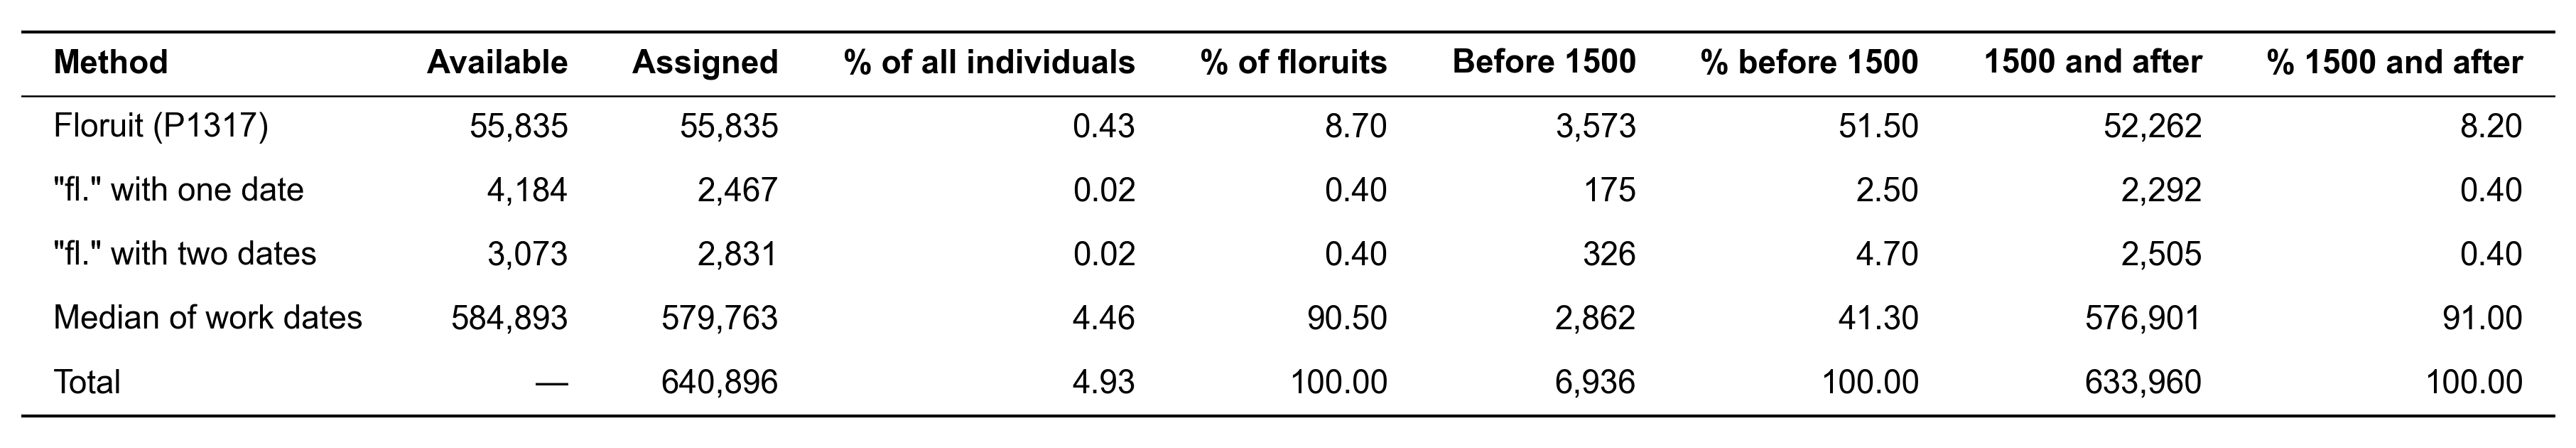

In [6]:
CUTOFF = 1500
available = {method: frame.height for method, frame in zip(METHODS, sources)}
coverage = (
    floruit.group_by('method').agg(
        pl.len().alias('assigned'),
        (pl.col('floruit_year') < CUTOFF).sum().alias('before'),
        (pl.col('floruit_year') >= CUTOFF).sum().alias('after'),
    )
    .with_columns(pl.col('method').replace_strict(available, return_dtype=pl.Int64).alias('available'))
    .sort(pl.col('method').replace_strict(METHODS, list(range(len(METHODS)))))
)
total = coverage.select(pl.lit('Total').alias('method'), pl.col('assigned', 'before', 'after').sum(), pl.lit(None, pl.Int64).alias('available'))
coverage = pl.concat([coverage, total.select(coverage.columns)])
assert (coverage['before'] + coverage['after'] == coverage['assigned']).all()
before_total, after_total = total['before'][0], total['after'][0]
show_table(coverage.select(
    pl.col('method').alias('Method'),
    pl.col('available').alias('Available'),
    pl.col('assigned').alias('Assigned'),
    (100 * pl.col('assigned') / database_size).round(2).alias('% of all individuals'),
    (100 * pl.col('assigned') / floruit.height).round(1).alias('% of floruits'),
    pl.col('before').alias(f'Before {CUTOFF}'),
    (100 * pl.col('before') / before_total).round(1).alias(f'% before {CUTOFF}'),
    pl.col('after').alias(f'{CUTOFF} and after'),
    (100 * pl.col('after') / after_total).round(1).alias(f'% {CUTOFF} and after'),
), decimals=2)

## Testing: one individual per century
The individual with the most Wikimedia pages whose floruit falls in the century, with their Wikidata birth and death.

In [7]:
connection.register('floruit', floruit.to_arrow())
examples = connection.execute(f'''
    SELECT floor(floruit.floruit_year / 100)::BIGINT * 100 AS century,
           coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || floruit.qid || ')' AS individual,
           coalesce(list_min([date.year FOR date IN individual.birth_date])::VARCHAR, '?') || ' – '
               || coalesce(list_min([date.year FOR date IN individual.death_date])::VARCHAR, '?') AS lifetime,
           floruit.floruit_year, floruit.method, floruit.qid
    FROM floruit
    JOIN individual ON individual.entity.qid = floruit.qid
    WHERE floor(floruit.floruit_year / 100) * 100 BETWEEN {FIRST_CENTURY} AND {LAST_CENTURY}
    QUALIFY row_number() OVER (PARTITION BY floor(floruit.floruit_year / 100) ORDER BY len(individual.sitelink) DESC, floruit.qid) = 1
    ORDER BY century
''').pl()
examples

century,individual,lifetime,floruit_year,method,qid
i64,str,str,i64,str,str
-1000,"""Mukin-abua (Q136374769)""","""? – ?""",-973,"""Floruit (P1317)""","""Q136374769"""
-900,"""Amos (Q213850)""","""-813 – -739""",-803,"""Median of work dates""","""Q213850"""
-800,"""Dipylon Master (Q943544)""","""-800 – -800""",-795,"""Floruit (P1317)""","""Q943544"""
-700,"""Polymedes of Argos (Q2673494)""","""-550 – ?""",-609,"""Median of work dates""","""Q2673494"""
-600,"""Sappho (Q17892)""","""-650 – -569""",-599,"""Floruit (P1317)""","""Q17892"""
-500,"""Sophocles (Q7235)""","""-495 – -405""",-444,"""Median of work dates""","""Q7235"""
-400,"""Aristotle (Q868)""","""-383 – -321""",-339,"""Median of work dates""","""Q868"""
-300,"""Archimedes (Q8739)""","""-286 – -211""",-235,"""Median of work dates""","""Q8739"""
-200,"""Cato the Elder (Q180081)""","""-233 – -148""",-170,"""Median of work dates""","""Q180081"""


### Table: one floruit per century, with an assessment
The assessment compares the floruit year with the individual's best-known period of activity. It was written by Claude from general historical knowledge, not checked against sources: **Yes** = within the peak of activity, **Close** = within about 50 years of it, **Too early** / **Too late** = outside it, **Unknown** = individual not known well enough to judge.

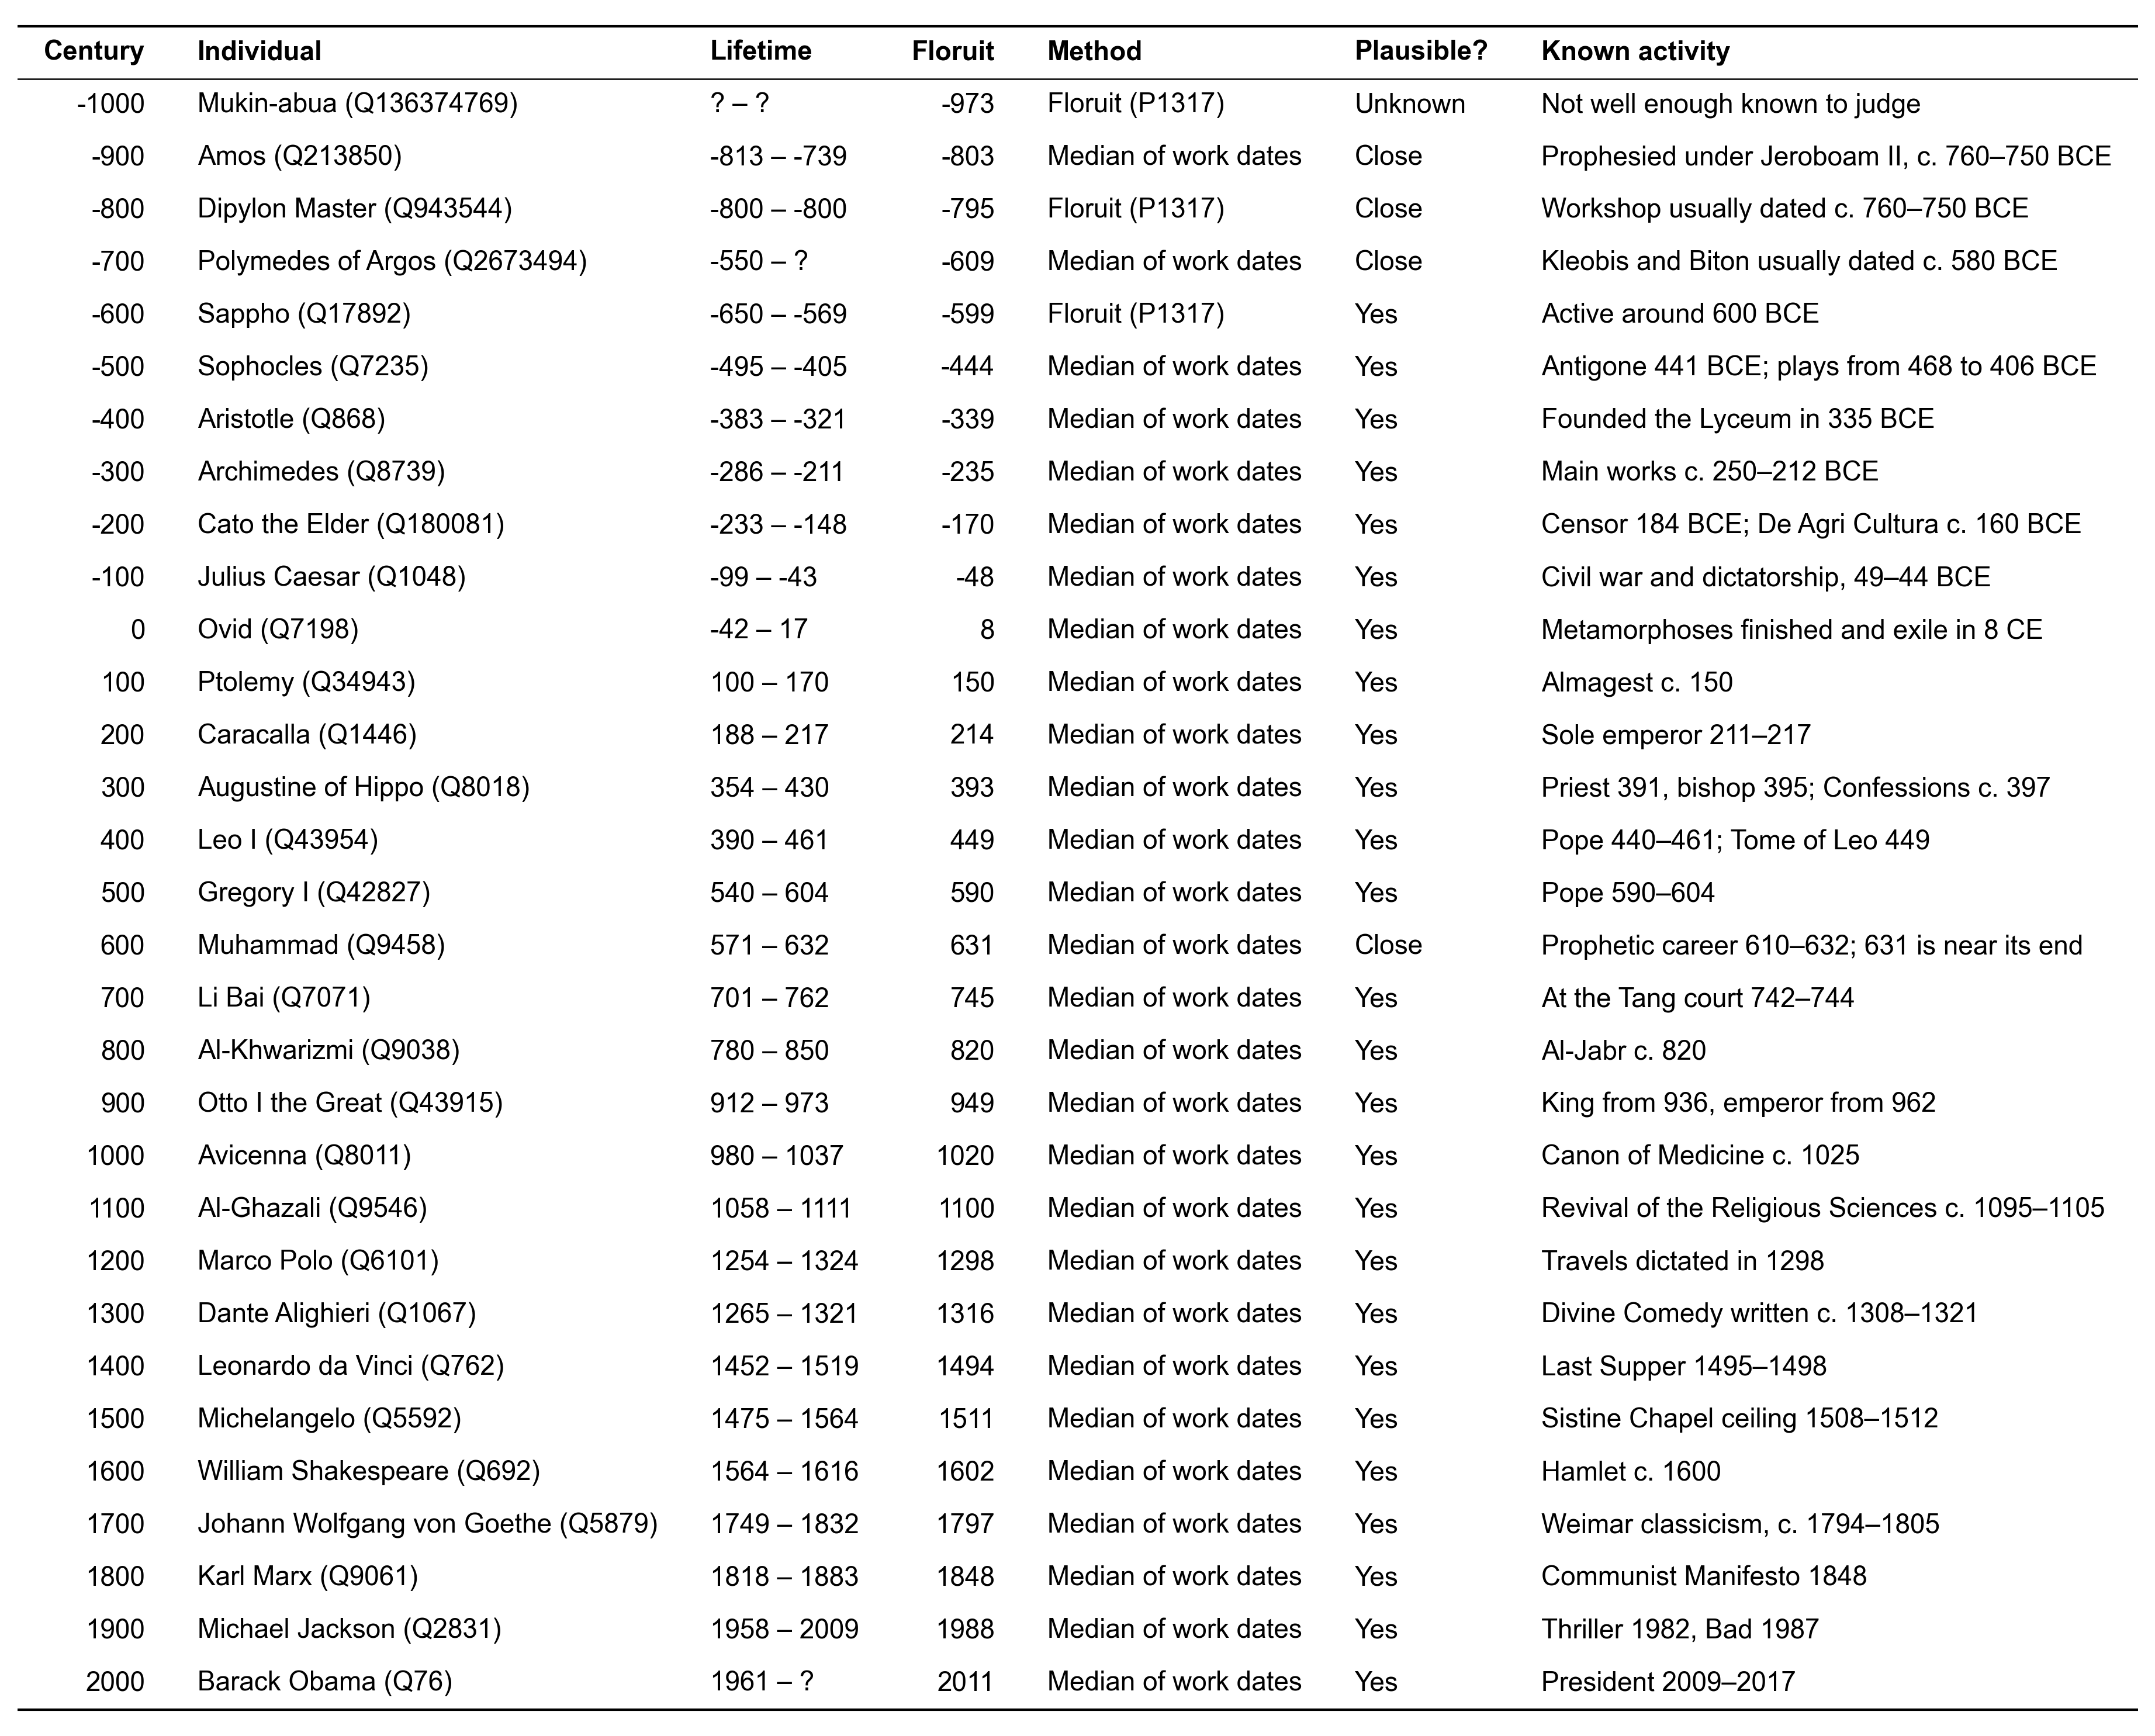

assessment,len
str,u32
"""Yes""",26
"""Close""",4
"""Unknown""",1


In [8]:
EVALUATION = {
    'Q136374769': ('Unknown', 'Not well enough known to judge'),
    'Q213850': ('Close', 'Prophesied under Jeroboam II, c. 760–750 BCE'),
    'Q943544': ('Close', 'Workshop usually dated c. 760–750 BCE'),
    'Q2673494': ('Close', 'Kleobis and Biton usually dated c. 580 BCE'),
    'Q17892': ('Yes', 'Active around 600 BCE'),
    'Q7235': ('Yes', 'Antigone 441 BCE; plays from 468 to 406 BCE'),
    'Q868': ('Yes', 'Founded the Lyceum in 335 BCE'),
    'Q8739': ('Yes', 'Main works c. 250–212 BCE'),
    'Q180081': ('Yes', 'Censor 184 BCE; De Agri Cultura c. 160 BCE'),
    'Q1048': ('Yes', 'Civil war and dictatorship, 49–44 BCE'),
    'Q7198': ('Yes', 'Metamorphoses finished and exile in 8 CE'),
    'Q34943': ('Yes', 'Almagest c. 150'),
    'Q1446': ('Yes', 'Sole emperor 211–217'),
    'Q8018': ('Yes', 'Priest 391, bishop 395; Confessions c. 397'),
    'Q43954': ('Yes', "Pope 440–461; Tome of Leo 449"),
    'Q42827': ('Yes', 'Pope 590–604'),
    'Q9458': ('Close', 'Prophetic career 610–632; 631 is near its end'),
    'Q7071': ('Yes', 'At the Tang court 742–744'),
    'Q9038': ('Yes', 'Al-Jabr c. 820'),
    'Q43915': ('Yes', 'King from 936, emperor from 962'),
    'Q8011': ('Yes', 'Canon of Medicine c. 1025'),
    'Q9546': ('Yes', 'Revival of the Religious Sciences c. 1095–1105'),
    'Q6101': ('Yes', 'Travels dictated in 1298'),
    'Q1067': ('Yes', 'Divine Comedy written c. 1308–1321'),
    'Q762': ('Yes', 'Last Supper 1495–1498'),
    'Q5592': ('Yes', 'Sistine Chapel ceiling 1508–1512'),
    'Q692': ('Yes', 'Hamlet c. 1600'),
    'Q5879': ('Yes', 'Weimar classicism, c. 1794–1805'),
    'Q9061': ('Yes', 'Communist Manifesto 1848'),
    'Q2831': ('Yes', 'Thriller 1982, Bad 1987'),
    'Q76': ('Yes', 'President 2009–2017'),
}
assert set(EVALUATION) == set(examples['qid']), set(examples['qid']) ^ set(EVALUATION)

evaluated = examples.with_columns(
    pl.col('qid').replace_strict({qid: verdict for qid, (verdict, _) in EVALUATION.items()}).alias('assessment'),
    pl.col('qid').replace_strict({qid: comment for qid, (_, comment) in EVALUATION.items()}).alias('known_activity'),
)
show_table(evaluated.select(
    pl.col('century').cast(pl.String).alias('Century'),
    pl.col('individual').alias('Individual'),
    pl.col('lifetime').alias('Lifetime'),
    pl.col('floruit_year').cast(pl.String).alias('Floruit'),
    pl.col('method').alias('Method'),
    pl.col('assessment').alias('Plausible?'),
    pl.col('known_activity').alias('Known activity'),
))
evaluated.group_by('assessment').len().sort('len', descending=True)

## Age at floruit and at the median work date
Two measures, each minus the Wikidata birth year (precise to the year or decade):
- **Floruit**: the Wikidata floruit (P1317) only.
- **Median work date**: the median of the individual's cleaned work dates (section 4).

Individuals without a birth are left out, since no age can be computed. Born from 800 BC to 1899, age kept between 10 and 100. The occupational category is the most frequent one among the individual's occupations (as in notebook 01); categories come from the enriched database, attached read-only.

In [9]:
connection.execute(f"ATTACH '{ENRICHED_DB_PATH}' AS enriched (READ_ONLY)")
active = pl.concat([floruit_property.select('qid'), work_median.select('qid')]).unique()
connection.register('active', active.to_arrow())
births = connection.execute('''
    WITH dated AS (
        SELECT individual.entity.qid AS qid,
               list_min([CASE WHEN date.precision = 'decade' THEN date.year + 5 ELSE date.year END
                         FOR date IN individual.birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year
        FROM individual
        JOIN active ON active.qid = individual.entity.qid
    ),
    held AS (
        SELECT individual.entity.qid AS qid,
               unnest(individual.occupation).entity.qid AS occupation_qid,
               generate_subscripts(individual.occupation, 1) AS position
        FROM individual
        JOIN dated ON dated.qid = individual.entity.qid
        WHERE dated.birth_year IS NOT NULL
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN enriched.occupation AS occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    )
    SELECT dated.qid, dated.birth_year, coalesce(main_meta_occupation.meta_occupation, 'Other') AS meta_occupation
    FROM dated
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = dated.qid
    WHERE dated.birth_year IS NOT NULL
''').pl()
assert births['qid'].is_unique().all()


def ages_from(activity, name):
    frame = activity.join(births, on='qid')
    print(f'{name}: {activity.height:,} individuals, {frame.height:,} with a birth', end='')
    frame = (
        frame.with_columns((pl.col('year') - pl.col('birth_year')).alias('age'),
                           (pl.col('birth_year') // PERIOD_WIDTH * PERIOD_WIDTH).alias('birth_period'))
        .filter(pl.col('birth_period').is_between(FIRST_PERIOD, LAST_PERIOD) & (pl.col('birth_year') <= LAST_YEAR))
    )
    print(f', {frame.height:,} born from {FIRST_PERIOD} to {LAST_YEAR}', end='')
    frame = frame.filter(pl.col('age').is_between(AGE_MIN, AGE_MAX))
    print(f', {frame.height:,} with an age of {AGE_MIN}-{AGE_MAX}')
    return frame


floruit_ages = ages_from(floruit_property, 'Wikidata floruit')
work_ages = ages_from(work_median, 'Median work date')
pl.concat([
    floruit_ages.group_by('meta_occupation').len().with_columns(pl.lit('floruit').alias('measure')),
    work_ages.group_by('meta_occupation').len().with_columns(pl.lit('median work date').alias('measure')),
]).pivot(on='measure', index='meta_occupation', values='len').sort('floruit', descending=True)

Wikidata floruit: 55,835 individuals, 17,036 with a birth, 7,141 born from -800 to 1899, 6,720 with an age of 10-100
Median work date: 584,893 individuals, 557,730 with a birth, 114,424 born from -800 to 1899, 114,014 with an age of 10-100


meta_occupation,floruit,median work date
str,u32,u32
"""Culture""",4215,72227
"""Other""",939,4738
"""Discovery/Science""",916,28609
"""Leadership""",546,8171
"""Sports/Games""",104,269


In [10]:
GROUPS = ['All', *OCCUPATION_COLORS]
GROUP_COLORS = {'All': MAIN_LINE_COLOR, **OCCUPATION_COLORS}


def period_label(start):
    end = min(start + PERIOD_WIDTH - 1, LAST_YEAR)
    return f'{-start}–{-end} BC' if end < 0 else f'{start}–{end}'


def box_stats(frame, by):
    return (
        frame.group_by(by)
        .agg(
            pl.len().alias('individuals'),
            pl.col('age').quantile(0.25, 'linear').alias('low'),
            pl.col('age').median().alias('median'),
            pl.col('age').quantile(0.75, 'linear').alias('high'),
        )
        .sort(by)
    )


def group_stats(frame):
    everyone = box_stats(frame.with_columns(pl.lit('All').alias('meta_occupation')), 'meta_occupation')
    stats = pl.concat([everyone, box_stats(frame, 'meta_occupation').filter(pl.col('meta_occupation').is_in(GROUPS))])
    return stats.sort(pl.col('meta_occupation').replace_strict(GROUPS, list(range(len(GROUPS)))))


def draw_boxes(ax, values, positions, width, color, medians, quartiles=None):
    ax.boxplot(values, positions=positions, widths=width, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color),
               medianprops=dict(color=color, linewidth=2), whiskerprops=dict(color=color), capprops=dict(color=color))
    for x, m in zip(positions, medians):
        ax.annotate(f'{m:.0f}', (x + width * 0.55, m), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE, color=color)
    for x, (low, high) in zip(positions, quartiles or []):
        for q in (low, high):
            ax.annotate(f'{q:.0f}', (x + width * 0.55, q), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)


def plot_periods(ax, frame, color, show_quartiles=False, show_counts=False, counts_on_top=False):
    stats = box_stats(frame, 'birth_period').filter(pl.col('individuals') >= MIN_INDIVIDUALS)
    starts = stats['birth_period'].to_list()
    x = np.array(starts) + PERIOD_WIDTH / 2
    values = [frame.filter(pl.col('birth_period') == start)['age'].to_numpy() for start in starts]
    quartiles = list(zip(stats['low'], stats['high'])) if show_quartiles else None
    draw_boxes(ax, values, x, PERIOD_WIDTH * 0.6, color, stats['median'], quartiles)
    ax.set_xticks(x)
    labels = [period_label(start) for start in starts]
    if show_counts:
        labels = [f'{label}\n(n = {n:,})' for label, n in zip(labels, stats['individuals'])]
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_xlim(FIRST_PERIOD, LAST_PERIOD + PERIOD_WIDTH)
    ax.set_ylim(0, AGE_MAX)
    if counts_on_top:
        ax.set_ylim(0, AGE_MAX + 25)
        ax.set_yticks(range(0, AGE_MAX + 1, 20))
        for xi, n in zip(x, stats['individuals']):
            ax.text(xi, AGE_MAX + 3, f'{n:,}', rotation=90, ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)
    ax.grid(axis='y')


def figure_groups(frame, ylabel):
    stats = group_stats(frame)
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for i, row in enumerate(stats.iter_rows(named=True)):
        group = row['meta_occupation']
        values = frame if group == 'All' else frame.filter(pl.col('meta_occupation') == group)
        draw_boxes(ax, [values['age'].to_numpy()], [i], 0.5, GROUP_COLORS[group], [row['median']], [(row['low'], row['high'])])
    ax.set_xticks(range(stats.height))
    ax.set_xticklabels([f"{row['meta_occupation']}\n(n = {row['individuals']:,})" for row in stats.iter_rows(named=True)])
    ax.set_xlim(-0.5, stats.height - 0.3)
    ax.set_ylim(0, AGE_MAX)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y')
    plt.tight_layout()
    plt.show()


def figure_periods(frame, ylabel):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    plot_periods(ax, frame, MAIN_LINE_COLOR, show_quartiles=True, show_counts=True)
    ax.set_xlabel('Birth period')
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()


def figure_occupation_periods(frame, ylabel):
    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_GRID, sharey=True)
    for ax, (occupation, color) in zip(axes.flat, OCCUPATION_COLORS.items()):
        ax.text(0.02, 0.98, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=color, va='top', fontweight='bold')
        plot_periods(ax, frame.filter(pl.col('meta_occupation') == occupation), color, show_quartiles=True, counts_on_top=True)
    for ax in axes[-1, :]:
        ax.set_xlabel('Birth period')
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

### Age at floruit (Wikidata P1317), all individuals and by occupational category
#### Data plotted

In [11]:
group_stats(floruit_ages)

meta_occupation,individuals,low,median,high
str,u32,f64,f64,f64
"""All""",6720,30.0,41.0,54.0
"""Culture""",4215,29.0,40.0,53.0
"""Discovery/Science""",916,32.0,42.0,55.0
"""Leadership""",546,35.0,46.0,58.0
"""Sports/Games""",104,28.75,37.0,53.0


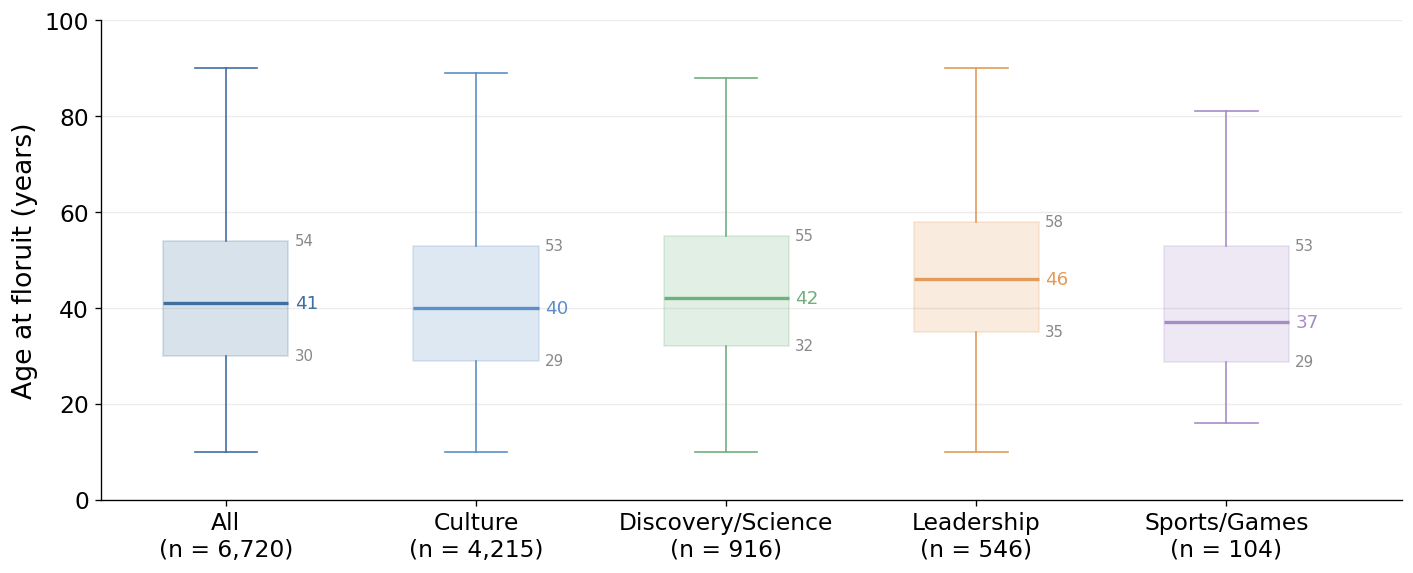

In [12]:
figure_groups(floruit_ages, 'Age at floruit (years)')

### Age at floruit (Wikidata P1317) per two-century birth period
#### Data plotted

In [13]:
period_stats = box_stats(floruit_ages, 'birth_period')
print(f"{period_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} periods with fewer than {MIN_INDIVIDUALS} individuals left out")
period_stats

3 periods with fewer than 5 individuals left out


birth_period,individuals,low,median,high
i64,u32,f64,f64,f64
-800,1,51.0,51.0,51.0
-600,4,52.75,67.0,73.0
-400,8,32.25,38.5,48.5
-200,11,31.5,46.0,54.5
0,8,31.75,40.0,58.75
200,9,25.0,29.0,45.0
400,10,21.25,46.5,56.0
600,3,14.0,15.0,25.5
800,9,29.0,34.0,43.0


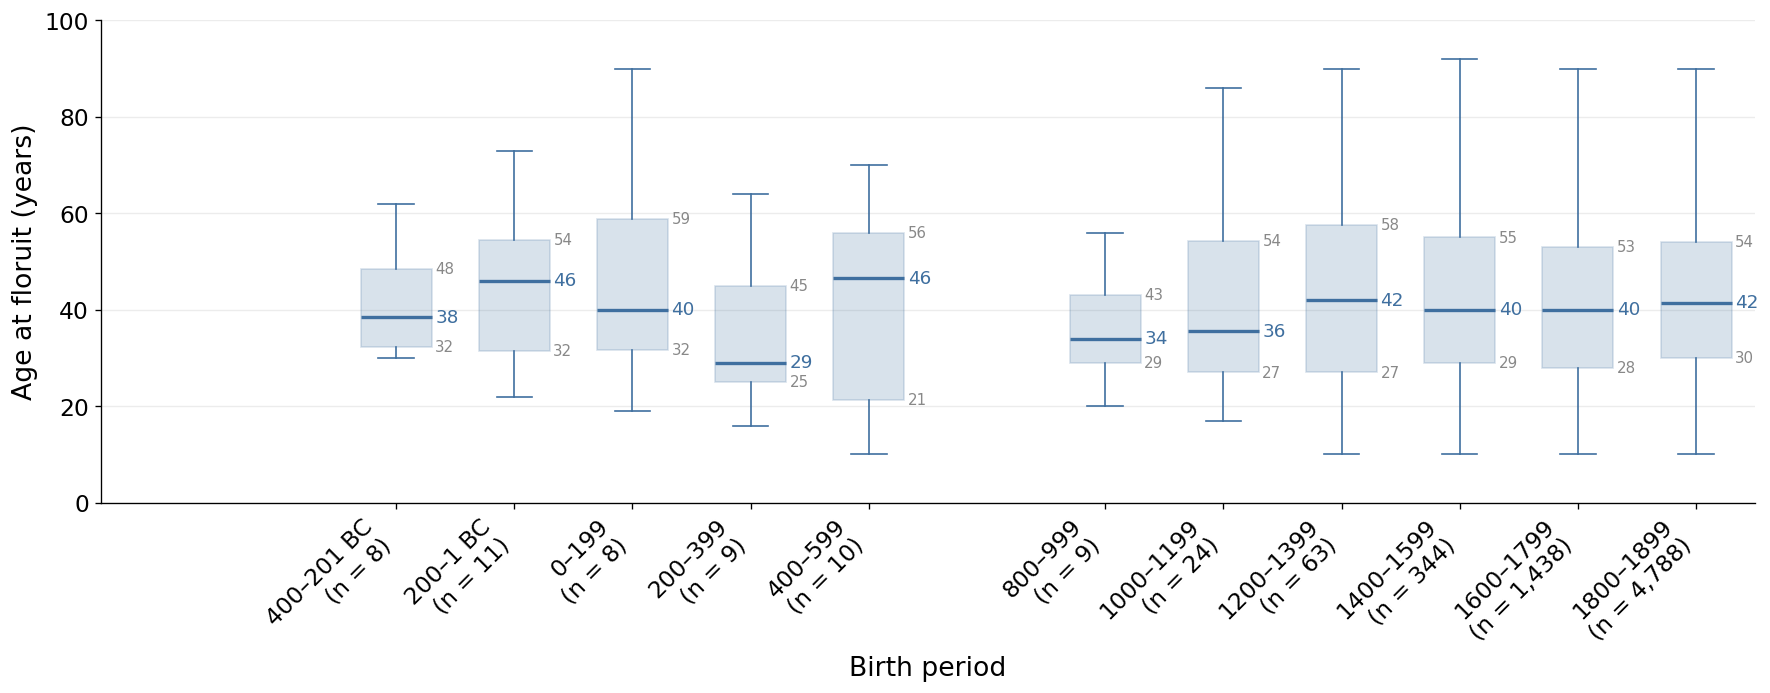

In [14]:
figure_periods(floruit_ages, 'Age at floruit (years)')

### Age at floruit (Wikidata P1317) per two-century birth period, by occupational category
#### Data plotted

In [15]:
box_stats(floruit_ages.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), ['meta_occupation', 'birth_period'])

meta_occupation,birth_period,individuals,low,median,high
str,i64,u32,f64,f64,f64
"""Culture""",-800,1,51.0,51.0,51.0
"""Culture""",-600,2,30.25,41.5,52.75
"""Culture""",-400,1,30.0,30.0,30.0
"""Culture""",-200,2,35.75,41.5,47.25
"""Culture""",0,1,19.0,19.0,19.0
"""Culture""",200,2,24.75,25.5,26.25
"""Culture""",400,1,70.0,70.0,70.0
"""Culture""",800,3,32.0,35.0,55.0
"""Culture""",1000,3,26.0,27.0,50.0


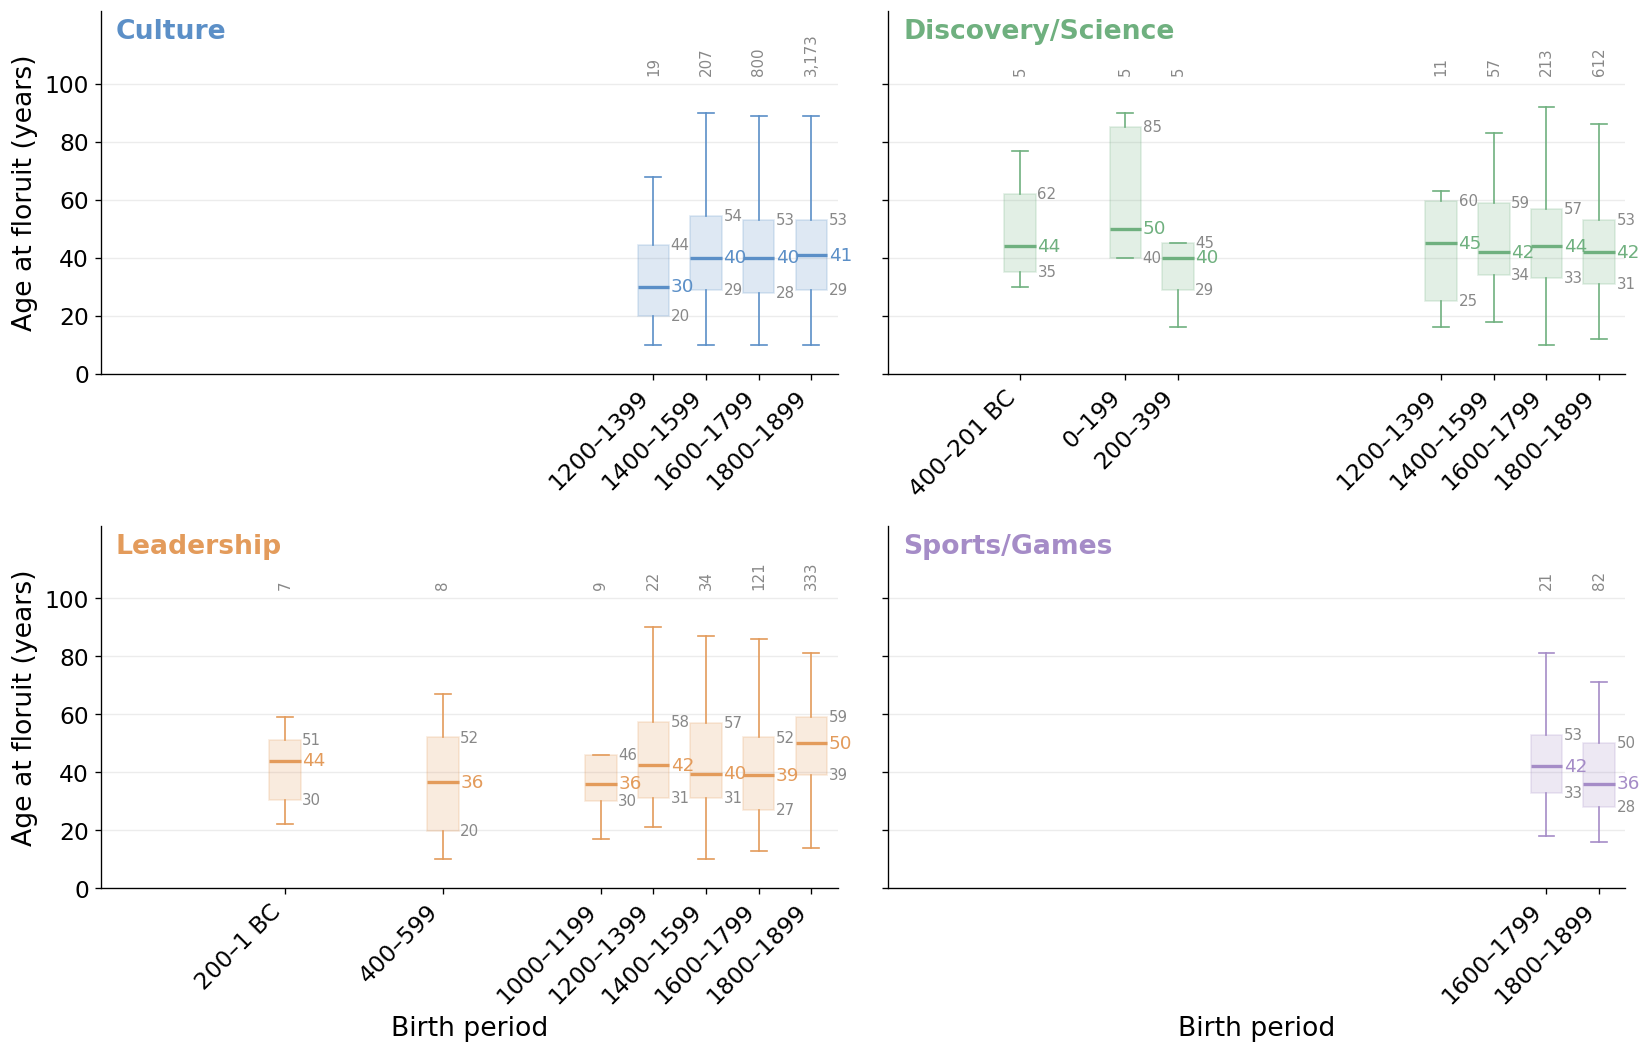

In [16]:
figure_occupation_periods(floruit_ages, 'Age at floruit (years)')

### Age at the median work date, all individuals and by occupational category
#### Data plotted

In [17]:
group_stats(work_ages)

meta_occupation,individuals,low,median,high
str,u32,f64,f64,f64
"""All""",114014,35.0,43.0,52.0
"""Culture""",72227,34.0,41.0,50.0
"""Discovery/Science""",28609,37.0,46.0,56.0
"""Leadership""",8171,37.0,48.0,58.0
"""Sports/Games""",269,34.0,43.0,55.0


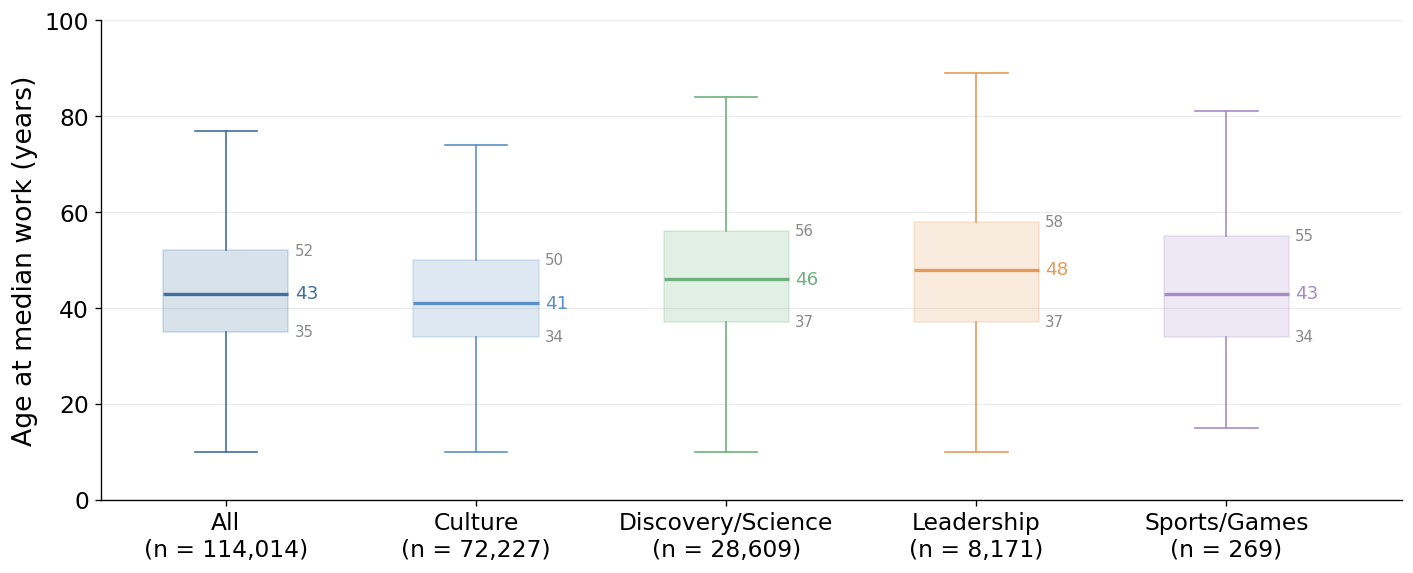

In [18]:
figure_groups(work_ages, 'Age at median work (years)')

### Age at the median work date per two-century birth period
#### Data plotted

In [19]:
period_stats = box_stats(work_ages, 'birth_period')
print(f"{period_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} periods with fewer than {MIN_INDIVIDUALS} individuals left out")
period_stats

1 periods with fewer than 5 individuals left out


birth_period,individuals,low,median,high
i64,u32,f64,f64,f64
-800,1,47.0,47.0,47.0
-600,17,40.0,48.0,53.0
-400,23,37.5,47.0,52.0
-200,19,41.5,51.0,58.5
0,31,37.0,50.0,60.5
200,42,35.25,41.0,52.75
400,52,39.75,50.5,58.5
600,72,41.0,48.5,60.0
800,119,37.5,47.0,57.5


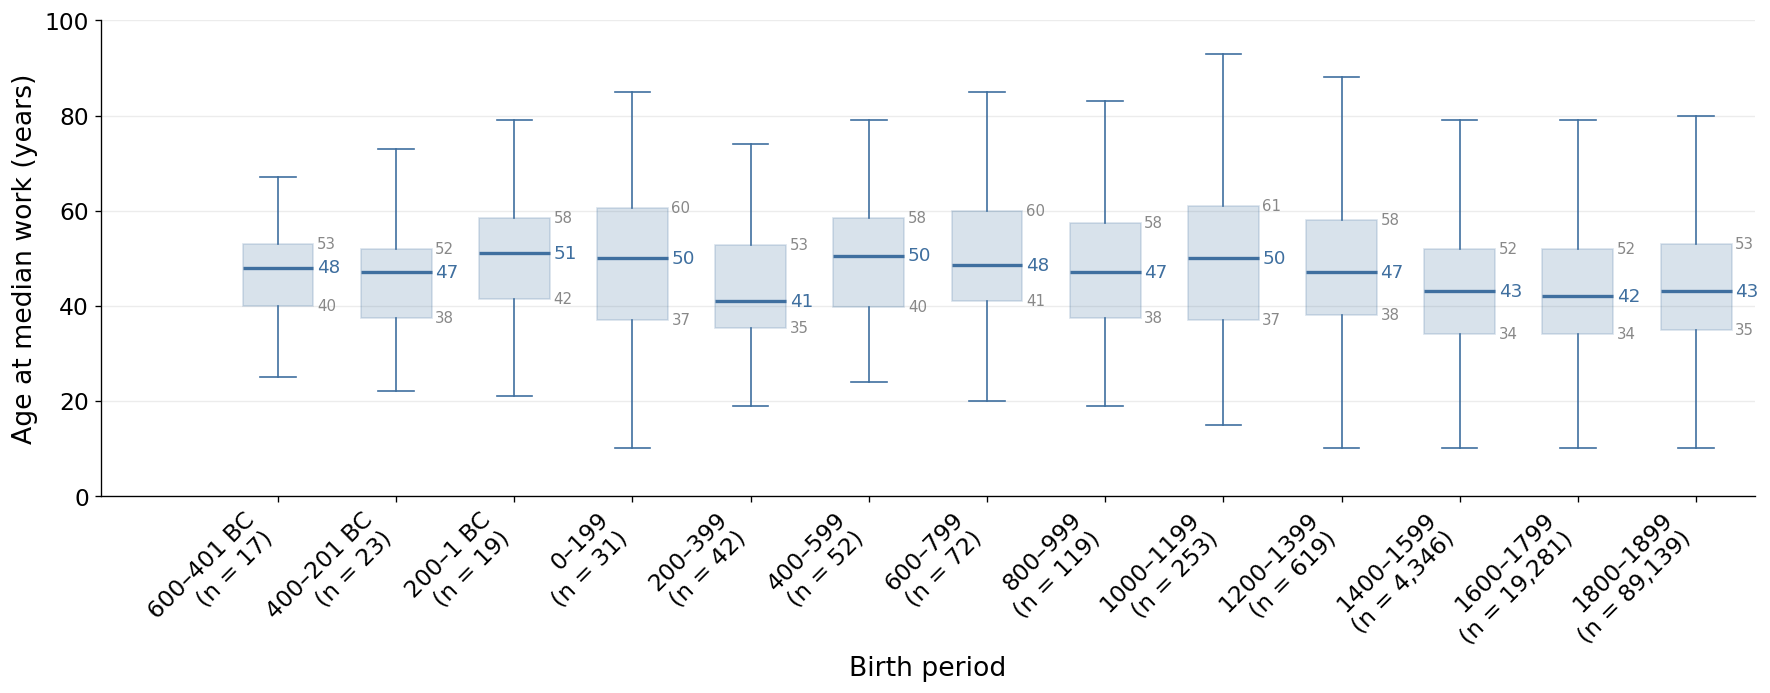

In [20]:
figure_periods(work_ages, 'Age at median work (years)')

### Age at the median work date per two-century birth period, by occupational category
#### Data plotted

In [21]:
box_stats(work_ages.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), ['meta_occupation', 'birth_period'])

meta_occupation,birth_period,individuals,low,median,high
str,i64,u32,f64,f64,f64
"""Culture""",-800,1,47.0,47.0,47.0
"""Culture""",-600,11,44.0,50.0,59.5
"""Culture""",-400,8,44.75,47.0,50.75
"""Culture""",-200,7,45.0,50.0,59.0
"""Culture""",0,9,41.0,50.0,62.0
"""Culture""",200,4,35.75,37.5,38.75
"""Culture""",400,14,36.75,52.0,57.75
"""Culture""",600,27,39.5,44.0,56.0
"""Culture""",800,30,36.0,44.5,57.0


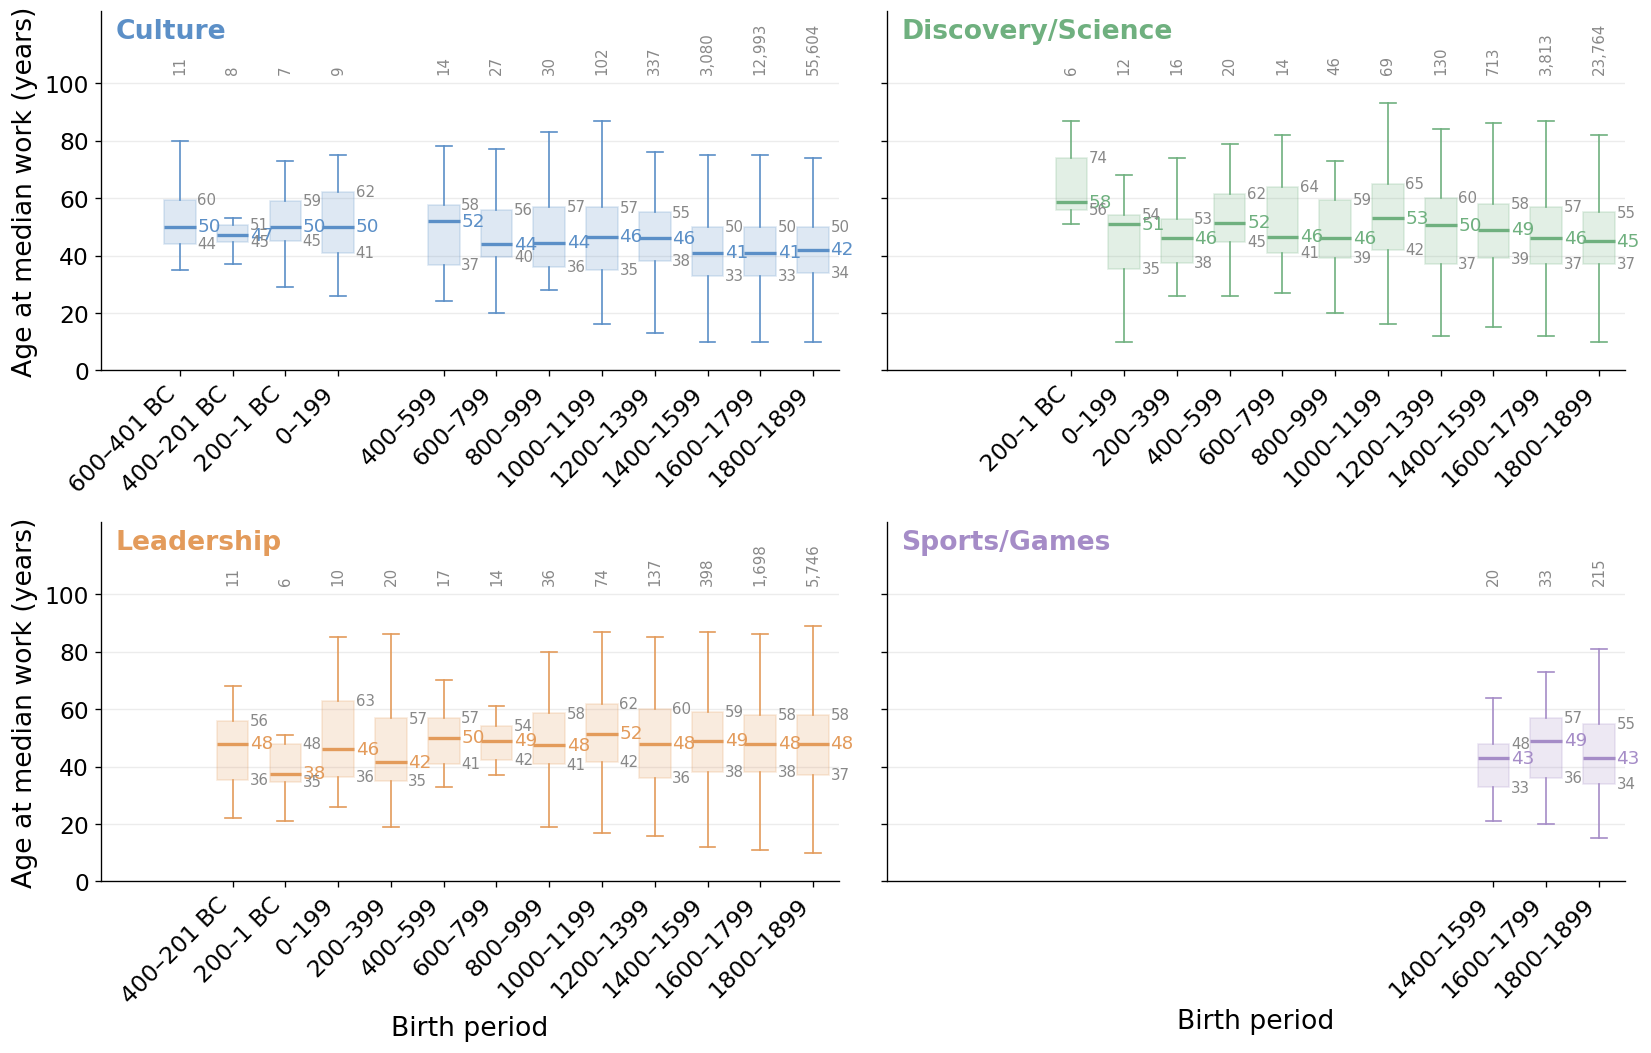

In [22]:
figure_occupation_periods(work_ages, 'Age at median work (years)')

### Floruit and median work date combined
One age per individual: the Wikidata floruit (P1317) when there is one, else the median work date.

In [23]:
columns = ['qid', 'birth_year', 'birth_period', 'meta_occupation', 'age']
combined_ages = pl.concat([
    floruit_ages.select(columns).with_columns(pl.lit('Floruit (P1317)').alias('source')),
    work_ages.join(floruit_ages, on='qid', how='anti').select(columns).with_columns(pl.lit('Median work date').alias('source')),
])
assert combined_ages['qid'].is_unique().all()
both = floruit_ages.join(work_ages, on='qid').height
print(f'{combined_ages.height:,} individuals, {both:,} of them with both (floruit kept)')
combined_ages.group_by('source').len()

119,560 individuals, 1,174 of them with both (floruit kept)


source,len
str,u32
"""Median work date""",112840
"""Floruit (P1317)""",6720


### Age at floruit or median work date, all individuals and by occupational category
#### Data plotted

In [24]:
group_stats(combined_ages)

meta_occupation,individuals,low,median,high
str,u32,f64,f64,f64
"""All""",119560,34.0,43.0,53.0
"""Culture""",75425,33.0,41.0,50.0
"""Discovery/Science""",29418,37.0,46.0,56.0
"""Leadership""",8694,37.0,48.0,58.0
"""Sports/Games""",368,33.0,42.0,54.0


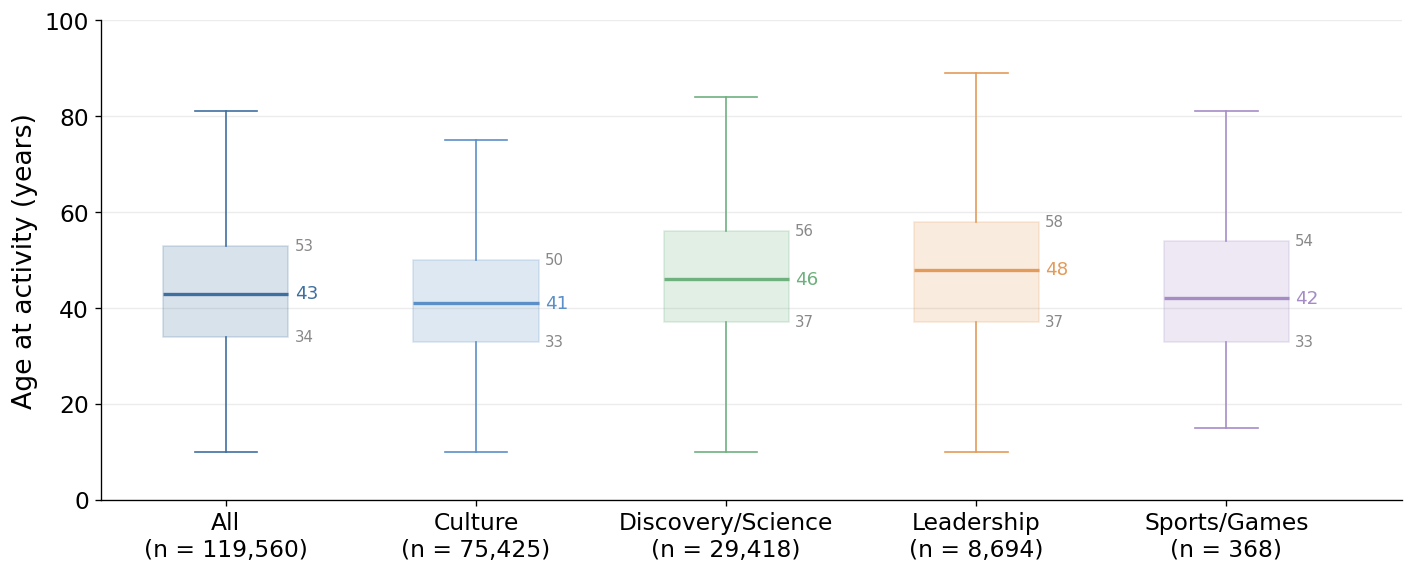

In [25]:
figure_groups(combined_ages, 'Age at activity (years)')

### Age at floruit or median work date per two-century birth period
#### Data plotted

In [26]:
period_stats = box_stats(combined_ages, 'birth_period')
print(f"{period_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} periods with fewer than {MIN_INDIVIDUALS} individuals left out")
period_stats

1 periods with fewer than 5 individuals left out


birth_period,individuals,low,median,high
i64,u32,f64,f64,f64
-800,2,48.0,49.0,50.0
-600,21,40.0,49.0,60.0
-400,31,36.0,46.0,52.0
-200,30,37.25,50.5,57.5
0,39,36.5,49.0,60.5
200,50,33.0,41.0,52.75
400,62,39.0,50.0,58.0
600,74,41.0,48.0,59.75
800,127,36.0,46.0,57.0


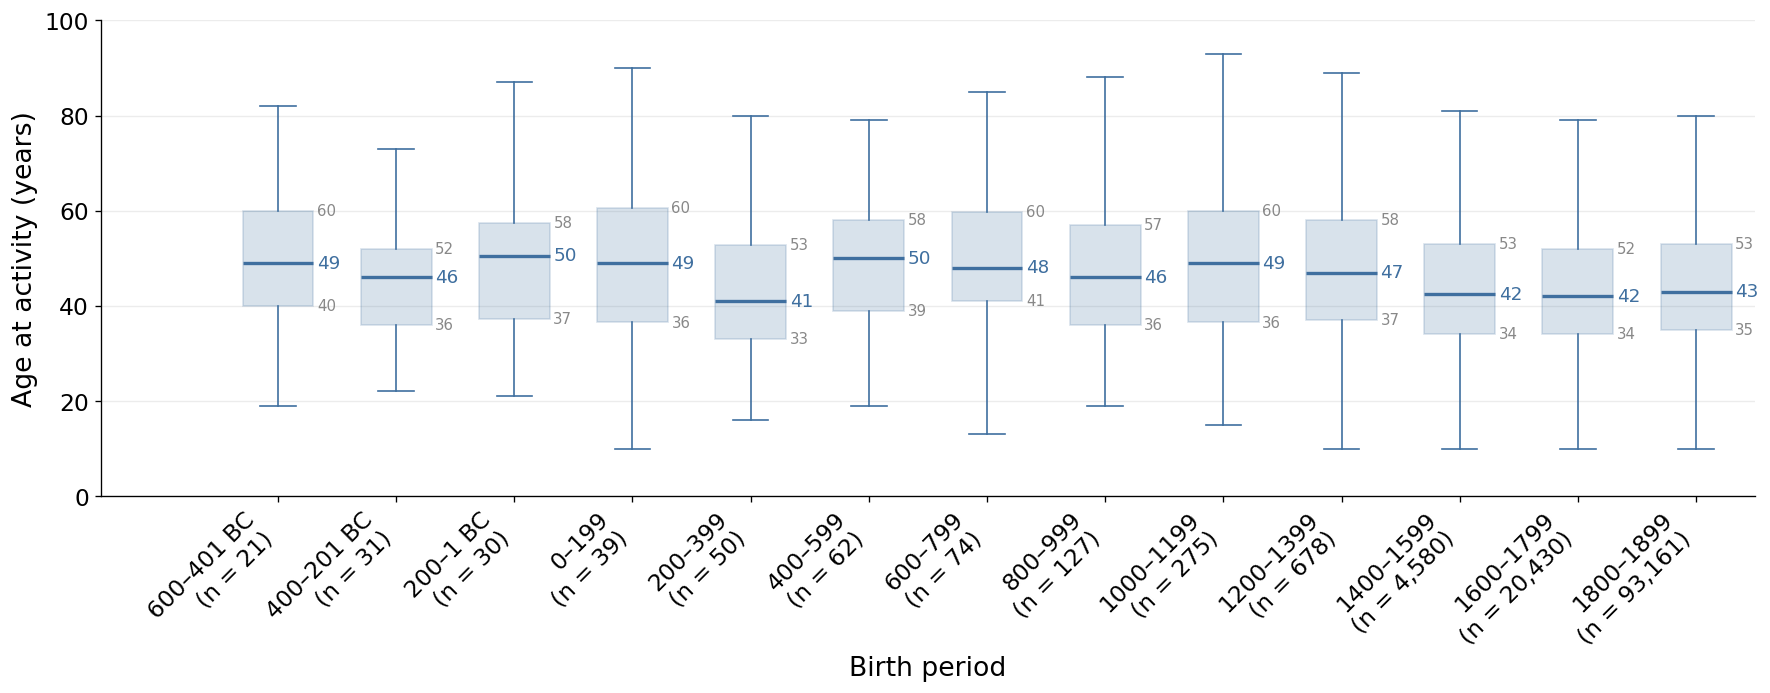

In [27]:
figure_periods(combined_ages, 'Age at activity (years)')

### Age at floruit or median work date per two-century birth period, by occupational category
#### Data plotted

In [28]:
box_stats(combined_ages.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), ['meta_occupation', 'birth_period'])

meta_occupation,birth_period,individuals,low,median,high
str,i64,u32,f64,f64,f64
"""Culture""",-800,2,48.0,49.0,50.0
"""Culture""",-600,13,44.0,50.0,60.0
"""Culture""",-400,9,41.0,47.0,50.0
"""Culture""",-200,9,45.0,50.0,53.0
"""Culture""",0,10,40.25,48.0,60.75
"""Culture""",200,6,28.25,34.5,37.75
"""Culture""",400,15,37.5,53.0,64.0
"""Culture""",600,27,39.5,44.0,56.0
"""Culture""",800,33,35.0,44.0,57.0


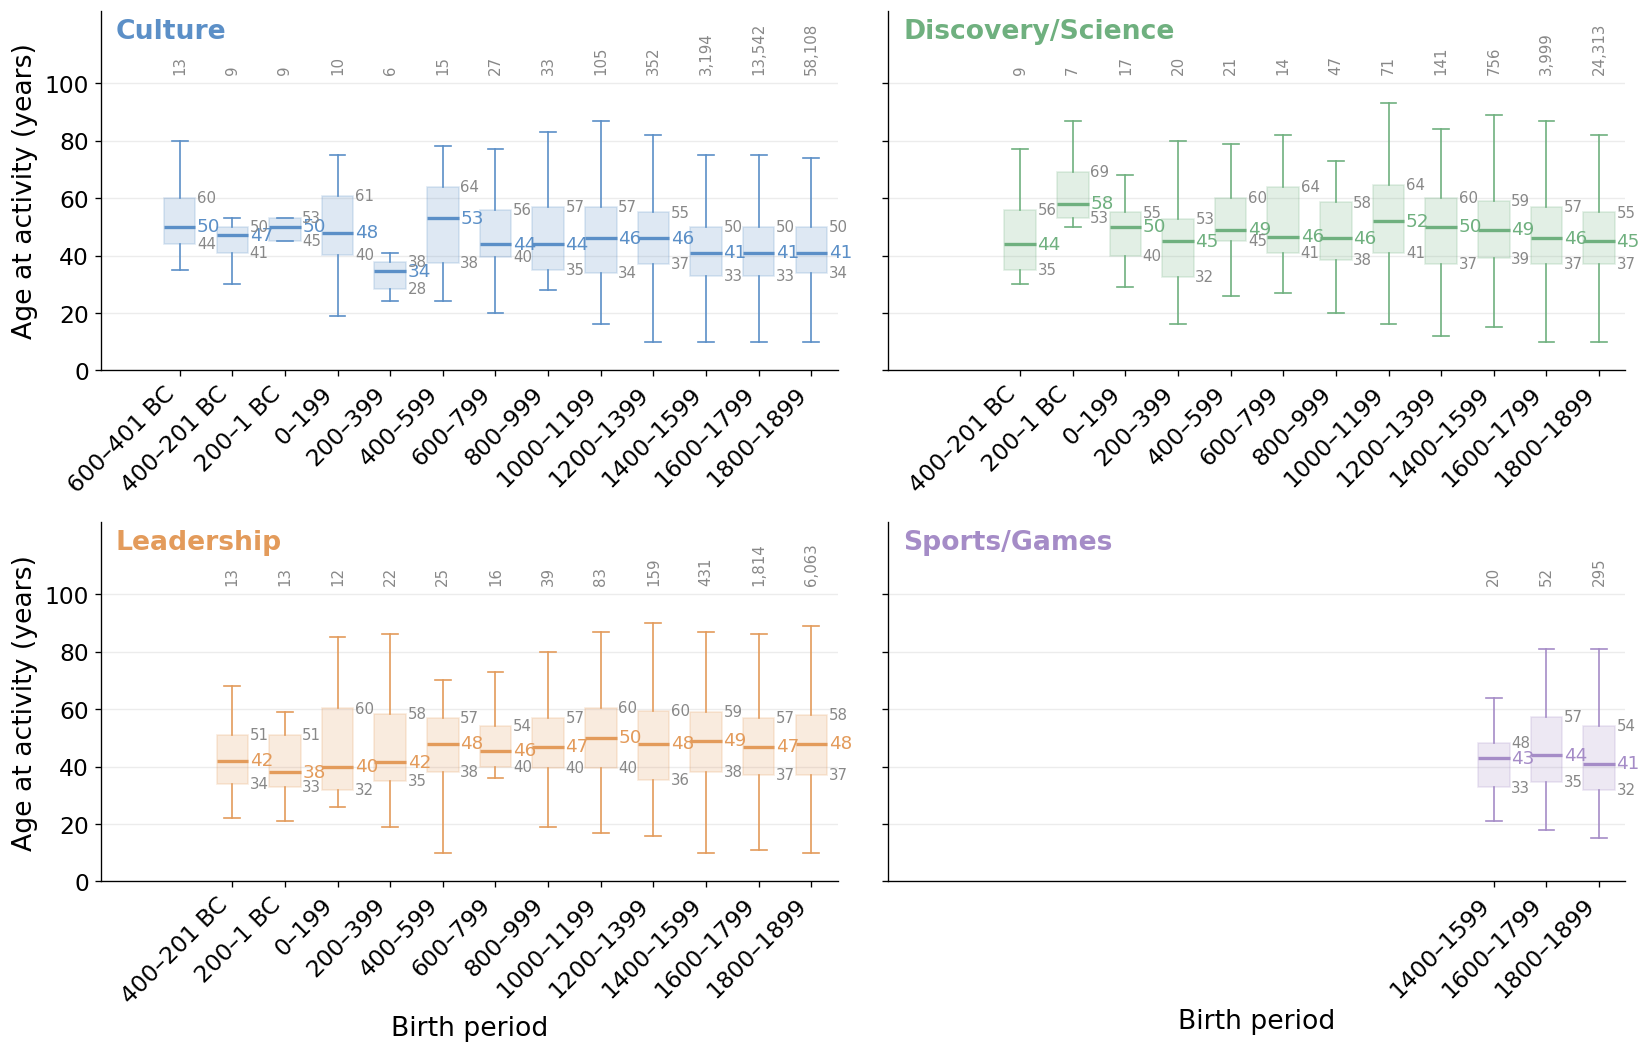

In [29]:
figure_occupation_periods(combined_ages, 'Age at activity (years)')